## 01 - Data Exploration, Cleaning & Feature Engineering

**Module:** IT5022 Fundamentals of Machine Learning
**Dataset:** NYC Taxi Trip Duration (Kaggle, 2016 NYC TLC records) — https://www.kaggle.com/competitions/nyc-taxi-trip-duration
**Task:** Supervised regression — predict `trip_duration` (seconds) at the moment a trip starts.

In [2]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42          # fixed seed so every run gives the same sample and split
SAMPLE_SIZE = 200_000      # rows used for modelling
TEST_SIZE = 0.20

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../report/figures", exist_ok=True)

### 1. Load the data

In [3]:
DATA_PATH = "../data/raw/train.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["pickup_datetime", "dropoff_datetime"])
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Loaded 1,458,644 rows x 11 columns


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [4]:
# Column types, missing values and duplicate IDs
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
})
print("Duplicate trip IDs:", df["id"].duplicated().sum())
overview

Duplicate trip IDs: 0


,dtype,missing,unique
id,str,0,1458644
vendor_id,int64,0,2
pickup_datetime,datetime64[us],0,1380222
dropoff_datetime,datetime64[us],0,1380377
passenger_count,int64,0,10
pickup_longitude,float64,0,23047
pickup_latitude,float64,0,45245
dropoff_longitude,float64,0,33821
dropoff_latitude,float64,0,62519
store_and_fwd_flag,str,0,2


### Attribute description

| Column | Meaning | Used as feature? |
|---|---|---|
| `id` | Unique trip identifier | No (identifier) |
| `vendor_id` | Data provider (1 or 2) | Yes |
| `pickup_datetime` | Meter start time | Yes, as hour / weekday / month |
| `dropoff_datetime` | Meter stop time | **No — dropoff minus pickup *is* the target (leakage)** |
| `passenger_count` | Driver-entered passenger count | Yes |
| `pickup_longitude/latitude` | Pickup GPS location | Yes |
| `dropoff_longitude/latitude` | Dropoff GPS location | Yes (destination is known when the trip is booked) |
| `store_and_fwd_flag` | Record held in vehicle memory before sending (Y/N) | Yes (0/1) |
| `trip_duration` | Trip length in seconds | **Target** |

### 2. Target variable

count    1458644.0
mean         959.5
std         5237.4
min            1.0
1%            87.0
50%          662.0
99%         3440.0
max      3526282.0
Name: trip_duration, dtype: float64


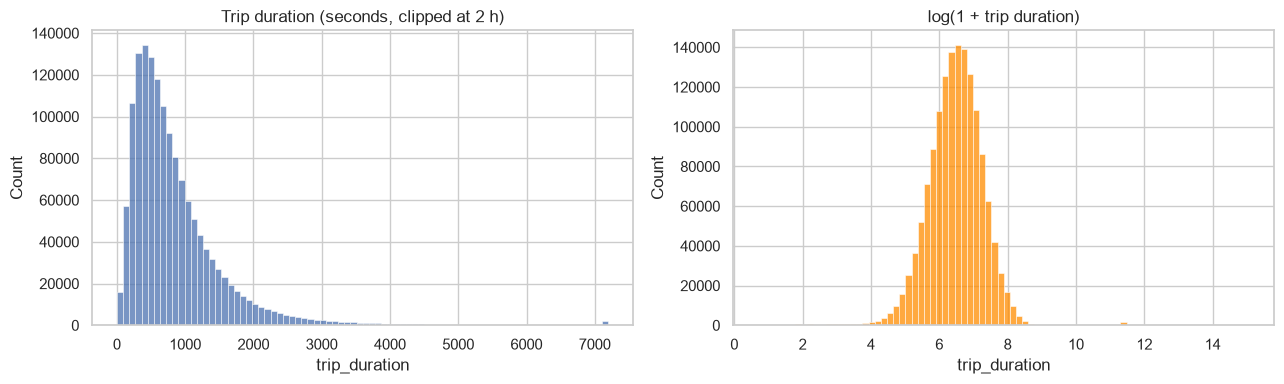

In [5]:
# Summary of the target, including the 1st and 99th percentiles
print(df["trip_duration"].describe(percentiles=[.01, .5, .99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["trip_duration"].clip(upper=7200), bins=80, ax=axes[0])
axes[0].set_title("Trip duration (seconds, clipped at 2 h)")
sns.histplot(np.log1p(df["trip_duration"]), bins=80, ax=axes[1], color="darkorange")
axes[1].set_title("log(1 + trip duration)")
plt.tight_layout()
plt.savefig("../report/figures/01_target_distribution.png", dpi=150)
plt.show()

The target is strongly right-skewed, with extreme values that are recording errors. After a log transform it is close
to bell-shaped, so both models will be trained on `log1p(trip_duration)`. Errors on the log scale are relative errors,
which matches the competition metric (RMSLE).

### 3. Exploratory analysis

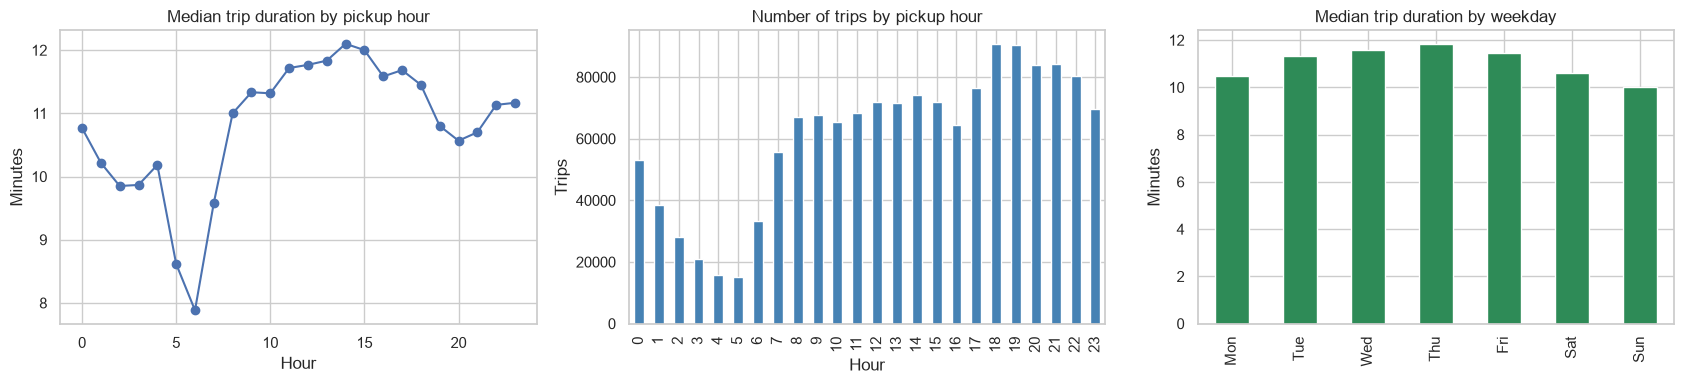

In [6]:
d = df.assign(hour=df["pickup_datetime"].dt.hour, weekday=df["pickup_datetime"].dt.dayofweek)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
d.groupby("hour")["trip_duration"].median().div(60).plot(ax=axes[0], marker="o")
axes[0].set(title="Median trip duration by pickup hour", xlabel="Hour", ylabel="Minutes")

d.groupby("hour").size().plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set(title="Number of trips by pickup hour", xlabel="Hour", ylabel="Trips")

day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
d.groupby("weekday")["trip_duration"].median().div(60).set_axis(day_names).plot(kind="bar", ax=axes[2], color="seagreen")
axes[2].set(title="Median trip duration by weekday", xlabel="", ylabel="Minutes")
plt.tight_layout()
plt.savefig("../report/figures/01_time_patterns.png", dpi=150)
plt.show()

In [7]:
# Counts per value for the categorical columns
for col in ["vendor_id", "passenger_count", "store_and_fwd_flag"]:
    print(df[col].value_counts().sort_index().to_string(), "\n")

vendor_id
1    678342
2    780302 

passenger_count
0         60
1    1033540
2     210318
3      59896
4      28404
5      78088
6      48333
7          3
8          1
9          1 

store_and_fwd_flag
N    1450599
Y       8045 



**Observations**

Starting with the target: a typical trip takes around 11 minutes (the median is 662 seconds), and 99% of trips are
over within an hour. The extremes don't make sense, though. The longest "trip" lasts about 41 days and the shortest
just one second, so these are clearly recording errors and need to be removed. There is also a small bump near the
24-hour mark (about 11.4 on the log scale), which looks like meters that were left running for a whole day.

The raw durations are heavily right-skewed, with a long tail of very long trips. Taking the log pulls this into
something close to a bell curve, which is why we model log(1 + duration) rather than the raw value.

Time of day makes a clear difference. Trips are quickest around 6 am, at roughly 8 minutes, and slowest around 2 pm,
at about 12 minutes, which fits with midday congestion. Durations creep up again late at night, but that is more
likely because people take longer trips at that hour than because of traffic.

Interestingly, the busiest hours are not the slowest ones. Demand peaks at 6–7 pm, with about 90k trips in each of
those hours, while the slowest trips happen at 2 pm. More trips on the road doesn't automatically mean slower trips.

The day of the week matters as well. Weekday trips take about a minute to a minute and a half longer than weekend
trips: Thursday is the slowest at around 11.8 minutes, and Sunday the quickest at about 10. That is what you would
expect with commuter and business traffic during the week.

On data quality, 65 trips have passenger counts that can't be right (0, or 7 to 9). `store_and_fwd_flag` is set to Y
for only 0.55% of trips, so it probably won't help the model much.

Taken together, hour of day and day of week look worth including as features, and the invalid records should be
cleaned out before training.

### 4. Data cleaning

Rules applied to the full dataset (each rule is counted so the effect can be reported):

1. **Location outside New York City** — pickup or dropoff outside a box covering the five boroughs and JFK/LaGuardia.
2. **Implausible duration** — under 60 seconds or over 2 hours.
3. **Invalid passenger count** — 0 or more than 6.
4. **No movement** — straight-line distance under 100 m.
5. **Impossible speed** — average speed above 100 km/h.

Rule 5 uses the trip duration, so it is only a *data-quality filter*: it removes records that cannot be real. The speed
itself is never given to a model.

In [8]:
def haversine_km(lat1, lon1, lat2, lon2):
    # Great-circle distance between two points on the Earth (in km)
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

def clean(data):
    audit = {"start": len(data)}

    # Rule 1: both pickup and dropoff inside the NYC box
    lat_ok = lambda c: data[c].between(40.57, 40.92)
    lon_ok = lambda c: data[c].between(-74.15, -73.70)
    keep = lat_ok("pickup_latitude") & lat_ok("dropoff_latitude") & lon_ok("pickup_longitude") & lon_ok("dropoff_longitude")
    audit["outside_nyc"] = int((~keep).sum()); data = data[keep]

    # Rule 2: duration between 1 minute and 2 hours
    keep = data["trip_duration"].between(60, 7200)
    audit["duration_outside_60s_2h"] = int((~keep).sum()); data = data[keep]

    # Rule 3: 1 to 6 passengers
    keep = data["passenger_count"].between(1, 6)
    audit["invalid_passengers"] = int((~keep).sum()); data = data[keep]

    # Rule 4: moved at least 100 metres
    dist = haversine_km(data["pickup_latitude"], data["pickup_longitude"], data["dropoff_latitude"], data["dropoff_longitude"])
    keep = dist >= 0.1
    audit["under_100m"] = int((~keep).sum()); data, dist = data[keep], dist[keep]

    # Rule 5: average speed no more than 100 km/h
    speed = dist / (data["trip_duration"] / 3600)
    keep = speed <= 100
    audit["speed_over_100kmh"] = int((~keep).sum()); data = data[keep]

    audit["end"] = len(data)
    audit["retained_pct"] = round(100 * audit["end"] / audit["start"], 2)
    return data.copy(), audit

df_clean, audit = clean(df)
pd.Series(audit, name="rows").to_frame()

,rows
start,1458644.00
outside_nyc,4282.00
duration_outside_60s_2h,10544.00
invalid_passengers,18.00
under_100m,7391.00
speed_over_100kmh,30.00
end,1436379.00
retained_pct,98.47


### 5. Feature engineering

Every feature below is available when the trip starts (pickup time, pickup and dropoff locations). Nothing is derived
from `trip_duration` or `dropoff_datetime`.

| Feature | Why it may help |
|---|---|
| `haversine_km` | Straight-line trip distance — the main driver of duration |
| `manhattan_km` | Grid distance; closer to real street routes in Manhattan |
| `bearing` | Direction of travel (crosstown vs. uptown traffic behaves differently) |
| `hour`, `weekday`, `month`, `is_weekend` | Traffic varies by time of day, day of week and season |
| `vendor_id`, `passenger_count`, `store_and_fwd` | Provider and booking details |
| coordinates | Where the trip starts and ends |
| `pickup_cluster`, `dropoff_cluster` | K-Means area IDs (added after the split, Section 7) |

In [9]:
def manhattan_km(lat1, lon1, lat2, lon2):
    # Distance travelled along a north-south leg plus an east-west leg
    return haversine_km(lat1, lon1, lat2, lon1) + haversine_km(lat2, lon1, lat2, lon2)

def bearing_deg(lat1, lon1, lat2, lon2):
    # Compass direction from pickup to dropoff, in degrees (-180 to 180)
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    y = np.sin(lon2 - lon1) * np.cos(lat2)
    x = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(lon2 - lon1)
    return np.degrees(np.arctan2(y, x))

def add_features(data):
    out = pd.DataFrame(index=data.index)
    coords = ["pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude"]
    for c in coords:
        out[c] = data[c]
    args = [data[c] for c in coords]
    out["haversine_km"] = haversine_km(*args)
    out["manhattan_km"] = manhattan_km(*args)
    out["bearing"] = bearing_deg(*args)
    t = data["pickup_datetime"]
    out["hour"] = t.dt.hour
    out["weekday"] = t.dt.dayofweek
    out["month"] = t.dt.month
    out["is_weekend"] = (out["weekday"] >= 5).astype(int)
    out["vendor_id"] = data["vendor_id"]
    out["passenger_count"] = data["passenger_count"]
    out["store_and_fwd"] = (data["store_and_fwd_flag"] == "Y").astype(int)
    return out

X_all = add_features(df_clean)      # features (inputs)
y_all = df_clean["trip_duration"]   # target (what we predict)
print("Features:", X_all.shape)
X_all.describe().T.round(3)

Features: (1436379, 14)


,count,mean,std,min,25%,50%,75%,max
pickup_latitude,1436379.0,40.751,0.028,40.572,40.737,40.754,40.768,40.912
pickup_longitude,1436379.0,-73.974,0.038,-74.141,-73.992,-73.982,-73.968,-73.708
dropoff_latitude,1436379.0,40.752,0.032,40.570,40.736,40.755,40.770,40.920
dropoff_longitude,1436379.0,-73.973,0.033,-74.149,-73.991,-73.980,-73.963,-73.700
haversine_km,1436379.0,3.425,3.818,0.100,1.254,2.112,3.883,40.335
manhattan_km,1436379.0,4.427,5.086,0.102,1.599,2.712,5.010,56.987
bearing,1436379.0,-15.649,104.741,-179.993,-126.075,8.988,53.788,180.000
hour,1436379.0,13.617,6.398,0.000,9.000,14.000,19.000,23.000
weekday,1436379.0,3.049,1.954,0.000,1.000,3.000,5.000,6.000
month,1436379.0,3.516,1.681,1.000,2.000,4.000,5.000,6.000


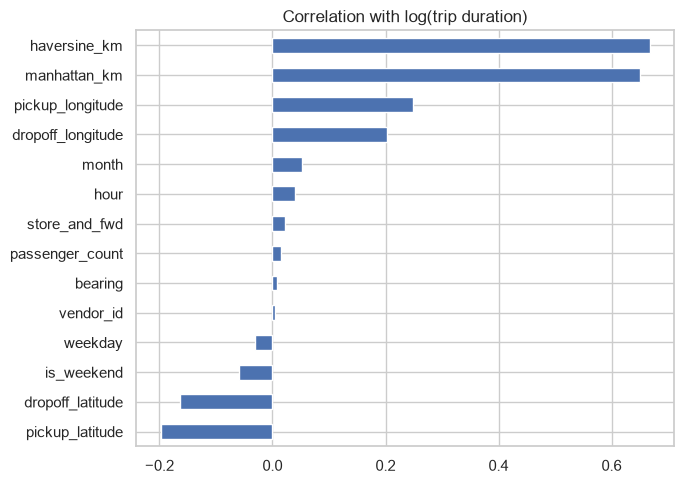

In [10]:
# Correlation of each feature with log duration (exploration only)
corr = X_all.assign(log_duration=np.log1p(y_all)).corr()["log_duration"].drop("log_duration").sort_values()
corr.plot(kind="barh", figsize=(7, 5), title="Correlation with log(trip duration)")
plt.tight_layout()
plt.savefig("../report/figures/01_feature_correlation.png", dpi=150)
plt.show()

**Observations**

Distance is by far the strongest predictor: both the haversine and Manhattan distances have a correlation of about 0.65 with log trip duration, while every other feature stays below 0.25. 

The location coordinates come next, with trips starting or ending further east and south (toward JFK and the outer boroughs) tending to take longer. 

The time features like hour and weekday look weak here, but that is because correlation only picks up straight-line relationships, and the hourly pattern we saw earlier rises and falls over the day rather than going steadily in one direction.

### 6. Sampling and train/test split

The cleaned data has over 1.4 million rows. Hyperparameter tuning with cross-validation means fitting each model many
times, which is not practical on a laptop with the full data. We therefore draw a **random sample of 200,000 trips**
(fixed seed) and split it 80/20. The test set is set aside and used only once, for the final evaluation.

In [11]:
X_s = X_all.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE)
y_s = y_all.loc[X_s.index]

X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")

# The sample should look like the full cleaned data
pd.DataFrame({"full_cleaned": y_all.describe(), "train": y_train.describe(), "test": y_test.describe()}).round(1)

Train: 160,000 rows | Test: 40,000 rows


,full_cleaned,train,test
count,1436379.0,160000.0,40000.0
mean,837.6,839.4,833.4
std,647.2,647.1,646.7
min,60.0,60.0,60.0
25%,401.0,403.0,399.0
50%,664.0,666.0,660.0
75%,1072.0,1076.2,1058.0
max,7191.0,7024.0,6925.0


### 7. K-Means location clusters (unsupervised preprocessing)

Raw coordinates are hard for a linear model to use. We group pickup and dropoff points into areas with K-Means and use
the area IDs as categorical features. K-Means is fitted on **training coordinates only**, then applied to the test set,
so no information from the test set leaks into training.

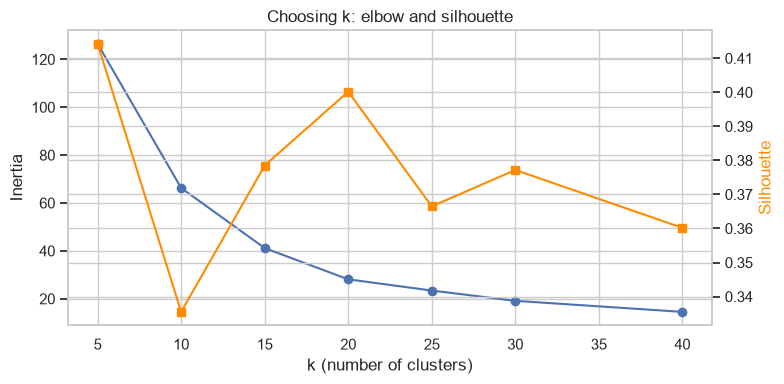

,k,inertia,silhouette
0,5,126.45,0.414
1,10,66.24,0.336
2,15,41.15,0.378
3,20,28.10,0.400
4,25,23.41,0.366
5,30,19.12,0.377
6,40,14.51,0.360


In [12]:
# Pickup and dropoff points from the training set only
train_points = np.vstack([
    X_train[["pickup_latitude", "pickup_longitude"]].values,
    X_train[["dropoff_latitude", "dropoff_longitude"]].values,
])

ks = [5, 10, 15, 20, 25, 30, 40]
inertia, sil = [], []
rng = np.random.default_rng(RANDOM_STATE)
sil_points = train_points[rng.choice(len(train_points), 10_000, replace=False)]
for k in ks:
    km = MiniBatchKMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=3, batch_size=10_000).fit(train_points)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(sil_points, km.predict(sil_points)))

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(ks, inertia, marker="o"); ax1.set(xlabel="k (number of clusters)", ylabel="Inertia")
ax2 = ax1.twinx(); ax2.plot(ks, sil, marker="s", color="darkorange"); ax2.set_ylabel("Silhouette", color="darkorange")
plt.title("Choosing k: elbow and silhouette"); plt.tight_layout()
plt.savefig("../report/figures/01_kmeans_k.png", dpi=150); plt.show()
pd.DataFrame({"k": ks, "inertia": np.round(inertia, 2), "silhouette": np.round(sil, 3)})

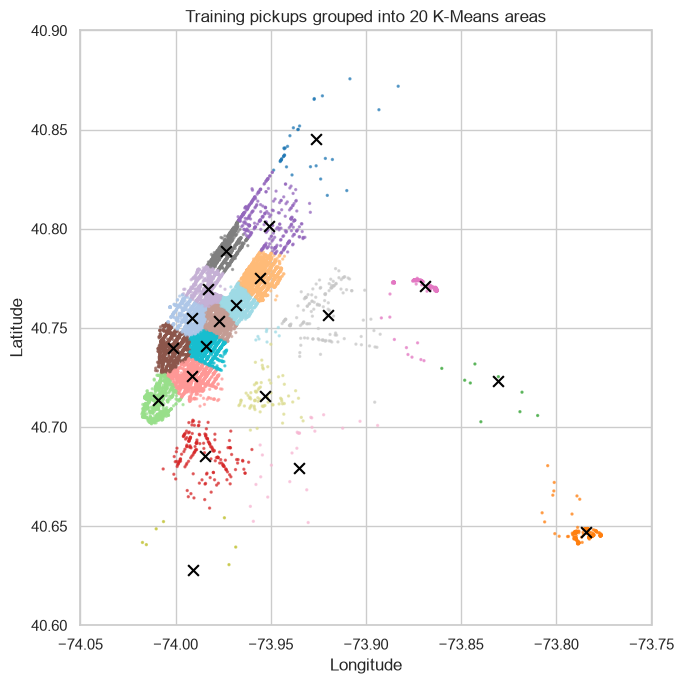

In [13]:
N_CLUSTERS = 20
kmeans = MiniBatchKMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=5, batch_size=10_000).fit(train_points)

for part in (X_train, X_test):
    part["pickup_cluster"] = kmeans.predict(part[["pickup_latitude", "pickup_longitude"]].values)
    part["dropoff_cluster"] = kmeans.predict(part[["dropoff_latitude", "dropoff_longitude"]].values)

# Map of training pickups coloured by cluster (sample ONCE so points and colours match)
pts = X_train.sample(15_000, random_state=RANDOM_STATE)
plt.figure(figsize=(7, 7))
plt.scatter(pts["pickup_longitude"], pts["pickup_latitude"], c=pts["pickup_cluster"], cmap="tab20", s=2, alpha=0.6)
centres = kmeans.cluster_centers_
plt.scatter(centres[:, 1], centres[:, 0], c="black", marker="x", s=60)
plt.xlim(-74.05, -73.75); plt.ylim(40.60, 40.90)
plt.title(f"Training pickups grouped into {N_CLUSTERS} K-Means areas")
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.tight_layout()
plt.savefig("../report/figures/01_kmeans_map.png", dpi=150); plt.show()

### 8. Leakage check and save

In [14]:
FEATURES = list(X_train.columns)
forbidden = {"trip_duration", "dropoff_datetime", "speed_kmh", "traffic_congestion_proxy", "fare_amount", "log_trip_duration"}
assert not forbidden & set(FEATURES), f"Leaky columns found: {forbidden & set(FEATURES)}"
print(f"{len(FEATURES)} features, none derived from the target:\n", FEATURES)

X_train.to_csv("../data/processed/X_train.csv", index=False)
X_test.to_csv("../data/processed/X_test.csv", index=False)
y_train.to_csv("../data/processed/y_train.csv", index=False)
y_test.to_csv("../data/processed/y_test.csv", index=False)
with open("../data/processed/cleaning_audit.json", "w") as f:
    json.dump(audit, f, indent=2)
print("Saved processed splits and cleaning audit to data/processed/")

16 features, none derived from the target:
 ['pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude', 'haversine_km', 'manhattan_km', 'bearing', 'hour', 'weekday', 'month', 'is_weekend', 'vendor_id', 'passenger_count', 'store_and_fwd', 'pickup_cluster', 'dropoff_cluster']
Saved processed splits and cleaning audit to data/processed/
